# ЛР08. Генерация и интерполяция в латентном пространстве

**Вариант 7:** набор сцен №2 `disc_rect` — «диск и полоса» (4 фактора сцены); фактор №1 — вес KL-члена, β = 1 → 8; seed 101…105.

## Гипотеза и допуск — зафиксированы до запуска (27.10.2026 21:00)

**Гипотеза.** При β = 8 KL-член «дорого» берёт за каждую используемую ось, и часть осей станет неактивной; в демо с тремя факторами при β = 8 активны две оси, а факторов здесь четыре. Поэтому реконструкция упадёт больше чем на 1 дБ, R² факторов — больше чем на 0,05, интерполяция — больше чем на 1 дБ; сэмплы изменятся в пределах ±1 дБ. Активных осей: при β = 1 — не меньше четырёх, при β = 8 — меньше четырёх.

**Допуск.** Реконструкция, интерполяция, сэмплы — ±1,0 дБ; R² — ±0,05. Рост любой метрики — улучшение. Фактор β меняет саму модель, поэтому контрольных метрик в варианте нет.

Вывод делается только после измерения и только для проверенных условий.

In [1]:
# Проверка GPU и фактических версий. Серию из пяти seed на процессоре не запускают.
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv
!pip list 2>/dev/null | grep -i -E "^(torch|numpy|pillow|matplotlib|pandas) "

import json, pathlib, platform, shutil, sys, time
from datetime import datetime, timezone
import numpy as np, torch, PIL

assert torch.cuda.is_available(), "CUDA GPU недоступен: выберите GPU T4 в настройках Colab"
environment = {
    "execution_environment": "Google Colab",
    "gpu": torch.cuda.get_device_name(0),
    "cuda_available": torch.cuda.is_available(),
    "cuda_runtime": torch.version.cuda,
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "packages": {"torch": torch.__version__, "numpy": np.__version__, "pillow": PIL.__version__},
    "started_at_utc": datetime.now(timezone.utc).isoformat(),
}
print(json.dumps(environment, ensure_ascii=False, indent=2))

name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07
matplotlib                            3.10.0
numpy                                 2.1.3
pandas                                2.2.3
pillow                                11.3.0
torch                                 2.11.0+cu130
{
  "execution_environment": "Google Colab",
  "gpu": "Tesla T4",
  "cuda_available": true,
  "cuda_runtime": "13.0",
  "python": "3.13.16",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "packages": {
    "torch": "2.11.0+cu130",
    "numpy": "2.1.3",
    "pillow": "11.3.0"
  },
  "started_at_utc": "2026-10-27T18:08:48.975529+00:00"
}


In [2]:
%%writefile lab07_lib.py
# ЛР 7. Построение автокодировщика. Библиотека учебных функций.
# Проверено 19.09.2026: Google Colab, GPU T4, Python 3.13, torch 2.11.0+cu128. Внешние данные не нужны: сцены порождаются кодом.
import time
import numpy as np
import torch
import torch.nn as nn

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N = 32                      # сторона изображения
SEEDS = range(101, 106)     # серия seed обучения
KINDS = ["disc", "disc_rect", "disc_noise", "disc_color", "two_discs"]   # пять контекстов (наборов данных)
N_FACTORS = {"disc": 3, "disc_rect": 4, "disc_noise": 3, "disc_color": 4, "two_discs": 4}
AMBER, GREEN, PINK = (1.0, 0.76, 0.29), (0.24, 0.86, 0.60), (0.95, 0.35, 0.55)
_YY, _XX = np.mgrid[0:N, 0:N] / (N - 1)


def _disc(img, cx, cy, r, color):
    m = (_XX - cx) ** 2 + (_YY - cy) ** 2 <= r * r
    for k in range(3):
        img[k][m] = color[k]


def _hue(h):
    """Простой цвет по параметру 0..1 (три сдвинутые косинусоиды)."""
    return tuple(0.5 + 0.5 * np.cos(2 * np.pi * (h + s)) for s in (0.0, 1 / 3, 2 / 3))


def render(kind, f):
    """Сцена 3×N×N по вектору факторов f из отрезка [0, 1]: положения и размеры объектов задают изображение однозначно."""
    img = np.zeros((3, N, N), dtype=np.float32)
    img[:] = (0.10 + 0.25 * (_XX + _YY) / 2)[None]
    if kind in ("disc", "disc_noise"):
        _disc(img, 0.25 + 0.5 * f[0], 0.25 + 0.5 * f[1], 0.12 + 0.10 * f[2], AMBER)
    elif kind == "disc_rect":
        _disc(img, 0.25 + 0.5 * f[0], 0.30 + 0.25 * f[1], 0.12 + 0.08 * f[2], AMBER)
        x0 = int((0.05 + 0.55 * f[3]) * N); img[:, int(0.72 * N):int(0.92 * N), x0:x0 + int(0.3 * N)] = np.array(GREEN)[:, None, None]
    elif kind == "disc_color":
        _disc(img, 0.25 + 0.5 * f[0], 0.25 + 0.5 * f[1], 0.12 + 0.10 * f[2], _hue(f[3]))
    elif kind == "two_discs":
        _disc(img, 0.15 + 0.3 * f[0], 0.15 + 0.7 * f[1], 0.12, AMBER)
        _disc(img, 0.55 + 0.3 * f[2], 0.15 + 0.7 * f[3], 0.12, PINK)
    else:
        raise ValueError(kind)
    return img


_CACHE = {}


def dataset(kind, n_train=4096, n_test=1024):
    """Обучающая и тестовая выборки (тензоры на устройстве) и факторы. Данные одинаковы для всех запусков (seed 7)."""
    if kind not in _CACHE:
        rng = np.random.default_rng(7)
        f = rng.random((n_train + n_test, N_FACTORS[kind]))
        x = np.stack([render(kind, fi) for fi in f])
        if kind == "disc_noise":
            x = np.clip(x + 0.05 * rng.standard_normal(x.shape).astype(np.float32), 0, 1)
        X = torch.tensor(x, dtype=torch.float32, device=DEVICE); F = torch.tensor(f, dtype=torch.float32, device=DEVICE)
        _CACHE[kind] = (X[:n_train], X[n_train:], F[:n_train], F[n_train:])
    return _CACHE[kind]


class ConvAE(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(3, 16, 4, 2, 1), nn.ReLU(), nn.Conv2d(16, 32, 4, 2, 1), nn.ReLU(),
                                 nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(), nn.Flatten(), nn.Linear(64 * 16, d))
        self.dec_fc = nn.Sequential(nn.Linear(d, 64 * 16), nn.ReLU())
        self.dec = nn.Sequential(nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(), nn.ConvTranspose2d(32, 16, 4, 2, 1), nn.ReLU(),
                                 nn.ConvTranspose2d(16, 3, 4, 2, 1), nn.Sigmoid())

    def encode(self, x):
        return self.enc(x)

    def decode(self, z):
        return self.dec(self.dec_fc(z).view(-1, 64, 4, 4))

    def forward(self, x):
        return self.decode(self.encode(x))


class DenseAE(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.enc = nn.Sequential(nn.Flatten(), nn.Linear(3 * N * N, 256), nn.ReLU(), nn.Linear(256, d))
        self.dec = nn.Sequential(nn.Linear(d, 256), nn.ReLU(), nn.Linear(256, 3 * N * N), nn.Sigmoid())

    def encode(self, x):
        return self.enc(x)

    def decode(self, z):
        return self.dec(z).view(-1, 3, N, N)

    def forward(self, x):
        return self.decode(self.encode(x))


def build(arch, d):
    return (ConvAE if arch == "conv" else DenseAE)(d).to(DEVICE)


def n_params(model):
    return sum(p.numel() for p in model.parameters())


def psnr_images(x, y):
    """Средний по изображениям PSNR, дБ (значения 0..1)."""
    mse = ((x - y) ** 2).flatten(1).mean(1).clamp_min(1e-10)
    return float((10 * torch.log10(1.0 / mse)).mean())


def train(model, Xtr, epochs=20, lr=2e-3, loss="mse", noise=0.0, seed=0, batch=128):
    """Обучение с Adam. loss: 'mse' или 'l1'. noise > 0: вход зашумляется (шумоподавляющий автокодировщик), цель — чистое изображение."""
    g = torch.Generator(device="cpu").manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    n = Xtr.shape[0]
    for _ in range(epochs):
        perm = torch.randperm(n, generator=g).to(DEVICE)
        for i in range(0, n, batch):
            x = Xtr[perm[i:i + batch]]
            xin = (x + noise * torch.randn(x.shape, generator=g).to(DEVICE)).clamp(0, 1) if noise > 0 else x
            out = model(xin)
            l = ((out - x) ** 2).mean() if loss == "mse" else (out - x).abs().mean()
            opt.zero_grad(); l.backward(); opt.step()
    return model


@torch.no_grad()
def reconstruct(model, X, eval_noise=0.0, seed=1234):
    model.eval()
    if eval_noise > 0:
        g = torch.Generator(device="cpu").manual_seed(seed)
        X = (X + eval_noise * torch.randn(X.shape, generator=g).to(DEVICE)).clamp(0, 1)
    return model(X)


# Шесть факторов: изменение базового режима A (свёрточный автокодировщик, d = 8, MSE, чистые данные, 4096 примеров).
FACTORS = ["latent_8_to_2", "latent_8_to_32", "arch_conv_to_dense", "loss_mse_to_l1", "input_clean_to_denoising", "train_4096_to_512"]
BASE = dict(arch="conv", d=8, loss="mse", noise=0.0, eval_noise=0.0, n_train=4096, epochs=20)


def settings(factor):
    a, b = dict(BASE), dict(BASE)
    if factor == "latent_8_to_2":
        b["d"] = 2
    elif factor == "latent_8_to_32":
        b["d"] = 32
    elif factor == "arch_conv_to_dense":
        b["arch"] = "dense"
    elif factor == "loss_mse_to_l1":
        b["loss"] = "l1"
    elif factor == "input_clean_to_denoising":
        a["eval_noise"] = b["eval_noise"] = 0.2; b["noise"] = 0.2
    elif factor == "train_4096_to_512":
        b["n_train"] = 512; b["epochs"] = 160   # 512 / 128 * 160 = 640 шагов, как 4096 / 128 * 20: число обновлений весов сохранено
    else:
        raise ValueError(factor)
    return a, b


def run(kind, cfg, seed):
    """Одно обучение: метрики на тестовой выборке."""
    Xtr, Xte, _, _ = dataset(kind)
    Xtr = Xtr[:cfg["n_train"]]
    torch.manual_seed(seed)
    t0 = time.perf_counter()
    model = train(build(cfg["arch"], cfg["d"]), Xtr, cfg["epochs"], loss=cfg["loss"], noise=cfg["noise"], seed=seed)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    p_te = psnr_images(reconstruct(model, Xte, cfg["eval_noise"]), Xte)
    p_tr = psnr_images(reconstruct(model, Xtr[:1024], cfg["eval_noise"]), Xtr[:1024])
    return dict(psnr=p_te, gap=p_tr - p_te, params=n_params(model) / 1000, seconds=dt), model


def variant_summary(n, seeds=SEEDS):
    """Вариант n = 1..30: набор данных c = (n-1)//6, фактор k = (n-1)%6. Для каждой метрики: A, s, B, разность, |d|/s, признак |d| > 2s."""
    c, k = (n - 1) // 6, (n - 1) % 6
    a_cfg, b_cfg = settings(FACTORS[k])
    A = {m: [] for m in ("psnr", "gap", "params", "seconds")}
    B = {m: [] for m in A}
    run(KINDS[c], a_cfg, 0)  # прогрев
    for s in seeds:
        ma, _ = run(KINDS[c], a_cfg, s)
        mb, _ = run(KINDS[c], b_cfg, s)
        for m in A:
            A[m].append(ma[m]); B[m].append(mb[m])
    rows = []
    for m in A:
        d = np.mean(B[m]) - np.mean(A[m]); sa = np.std(A[m], ddof=1)
        rows.append((m, float(np.mean(A[m])), float(sa), float(np.mean(B[m])), float(d), float(abs(d) / sa) if sa > 0 else float("inf"), bool(abs(d) > 2 * sa)))
    return dict(variant=n, ctx=c + 1, factor=FACTORS[k], rows=rows)


Writing lab07_lib.py


In [3]:
%%writefile lab08_lib.py
# ЛР 8. Генерация и интерполяция в латентном пространстве. Библиотека учебных функций.
# Требуется файл lab07_lib.py из ЛР 7 в той же папке (из него берутся сцены, устройство и базовые слои).
# Проверено 19.09.2026: Google Colab (GPU T4, torch 2.11.0+cu128) и Engee 26.8.2-H3 (процессор, Python 3.11, torch 2.4.1).
import numpy as np
import torch
import torch.nn as nn
import lab07_lib as L

torch.set_num_threads(min(4, torch.get_num_threads()))   # в Engee по умолчанию видно 112 потоков при 5 ядрах — это замедляет обучение в разы
DEVICE, SEEDS, KINDS = L.DEVICE, L.SEEDS, L.KINDS
N_PAIRS = 200      # пар изображений для проверки интерполяции
N_SAMPLES = 256    # число случайных сэмплов из априорного распределения


class ConvVAE(L.ConvAE):
    """Тот же свёрточный автокодировщик, но кодировщик выдаёт среднее и логарифм дисперсии латентного вектора."""
    def __init__(self, d):
        super().__init__(d)
        self.enc = nn.Sequential(*list(self.enc.children())[:-1])   # без последнего линейного слоя
        self.fc_mu, self.fc_lv = nn.Linear(64 * 16, d), nn.Linear(64 * 16, d)

    def encode_dist(self, x):
        h = self.enc(x)
        return self.fc_mu(h), self.fc_lv(h)

    def encode(self, x):
        return self.encode_dist(x)[0]

    def forward(self, x):
        mu, lv = self.encode_dist(x)
        return self.decode(mu), mu, lv


def train_vae(model, Xtr, beta, epochs=30, lr=2e-3, seed=0, batch=128, warmup=10):
    """Потери: сумма квадратов ошибок по пикселям + beta * KL (на изображение). beta = 0 даёт обычный автокодировщик (используется среднее).
    Вес KL-члена растёт линейно от 0 до beta за первые warmup эпох: без «разогрева» часть запусков схлопывается (все изображения кодируются одинаково)."""
    g = torch.Generator(device="cpu").manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    n = Xtr.shape[0]
    for epoch in range(epochs):
        perm = torch.randperm(n, generator=g).to(DEVICE)
        for i in range(0, n, batch):
            x = Xtr[perm[i:i + batch]]
            mu, lv = model.encode_dist(x)
            z = mu if beta == 0 else mu + torch.exp(0.5 * lv) * torch.randn(mu.shape, generator=g).to(DEVICE)
            rec = ((model.decode(z) - x) ** 2).flatten(1).sum(1).mean()
            kl = (-0.5 * (1 + lv - mu ** 2 - lv.exp()).sum(1)).mean()
            w = beta * min(1.0, (epoch + i / n) / warmup)
            loss = rec + w * kl if beta > 0 else rec
            opt.zero_grad(); loss.backward(); opt.step()
    return model


def slerp(za, zb, t):
    """Сферическая интерполяция; для почти коллинеарных векторов — линейная."""
    na, nb = za.norm(dim=-1, keepdim=True), zb.norm(dim=-1, keepdim=True)
    cos = ((za * zb).sum(-1, keepdim=True) / (na * nb).clamp_min(1e-8)).clamp(-1, 1)
    om = torch.acos(cos)
    so = torch.sin(om)
    w = torch.where(so.abs() < 1e-4, torch.full_like(so, 1.0), so)
    lin = (1 - t) * za + t * zb
    sph = (torch.sin((1 - t) * om) / w) * za + (torch.sin(t * om) / w) * zb
    return torch.where(so.abs() < 1e-4, lin, sph)


_TARGETS = {}


def interp_targets(kind):
    """Эталонные сцены для середины интерполяции: сцена, построенная по средним значениям факторов пары (истинная «середина»)."""
    if kind not in _TARGETS:
        _, _, _, Fte = L.dataset(kind)
        rng = np.random.default_rng(11)
        ia, ib = rng.integers(0, Fte.shape[0], N_PAIRS), rng.integers(0, Fte.shape[0], N_PAIRS)
        f = Fte.cpu().numpy()
        tg = {t: torch.tensor(np.stack([L.render(kind, (1 - t) * f[a] + t * f[b]) for a, b in zip(ia, ib)]), device=DEVICE) for t in (0.25, 0.5, 0.75)}
        _TARGETS[kind] = (torch.tensor(ia, device=DEVICE), torch.tensor(ib, device=DEVICE), tg)
    return _TARGETS[kind]


@torch.no_grad()
def metrics(model, kind, interp="lin", temp=1.0, seed=0):
    """Четыре показателя: PSNR реконструкции; PSNR интерполяции (по трём точкам пути) относительно истинной сцены;
    PSNR ближайшего соседа для случайных сэмплов из N(0, temp^2 I) в тестовой выборке; средний R^2 линейного восстановления факторов по среднему."""
    model.eval()
    Xtr, Xte, Ftr, Fte = L.dataset(kind)
    mu_te = model.encode(Xte)
    recon = L.psnr_images(model.decode(mu_te), Xte)
    ia, ib, tg = interp_targets(kind)
    za, zb = mu_te[ia], mu_te[ib]
    vals = []
    for t, target in tg.items():
        z = slerp(za, zb, t) if interp == "slerp" else (1 - t) * za + t * zb
        vals.append(L.psnr_images(model.decode(z), target))
    g = torch.Generator(device="cpu").manual_seed(1000 + seed)
    zs = temp * torch.randn((N_SAMPLES, mu_te.shape[1]), generator=g).to(DEVICE)
    xs = model.decode(zs).flatten(1)
    mse = torch.cdist(xs, Xte.flatten(1)).pow(2) / xs.shape[1]
    nn_psnr = float((10 * torch.log10(1.0 / mse.min(1).values.clamp_min(1e-10))).mean())
    mu_tr = model.encode(Xtr)
    A = torch.cat([mu_tr, torch.ones(mu_tr.shape[0], 1, device=DEVICE)], 1).double()
    W = torch.linalg.solve(A.T @ A + 1e-6 * torch.eye(A.shape[1], device=DEVICE, dtype=A.dtype), A.T @ Ftr.double()).float()
    pred = torch.cat([mu_te, torch.ones(mu_te.shape[0], 1, device=DEVICE)], 1) @ W
    r2 = 1 - ((pred - Fte) ** 2).sum(0) / ((Fte - Fte.mean(0)) ** 2).sum(0)
    return dict(recon=recon, interp=float(np.mean(vals)), sample=nn_psnr, r2=float(r2.mean()))


# Шесть факторов; базовый режим A: VAE, d = 8, beta = 1, линейная интерполяция, сэмплы из N(0, I).
FACTORS = ["beta_1_to_8", "ae_to_vae", "latent_8_to_2", "latent_8_to_32", "interp_linear_to_slerp", "sample_temp_1_to_2"]
BASE = dict(d=8, beta=1.0, interp="lin", temp=1.0, epochs=30)


def settings(factor):
    a, b = dict(BASE), dict(BASE)
    if factor == "beta_1_to_8":
        b["beta"] = 8.0
    elif factor == "ae_to_vae":
        a["beta"] = 0.0
    elif factor == "latent_8_to_2":
        b["d"] = 2
    elif factor == "latent_8_to_32":
        b["d"] = 32
    elif factor == "interp_linear_to_slerp":
        b["interp"] = "slerp"
    elif factor == "sample_temp_1_to_2":
        b["temp"] = 2.0
    else:
        raise ValueError(factor)
    return a, b


_MODELS = {}


def get_model(kind, cfg, seed):
    """Модель обучается один раз для каждой комбинации (набор данных, d, beta, число эпох, seed): факторы интерполяции и температуры используют одну модель."""
    key = (kind, cfg["d"], cfg["beta"], cfg["epochs"], seed)
    if key not in _MODELS:
        Xtr = L.dataset(kind)[0]
        torch.manual_seed(seed)
        _MODELS[key] = train_vae(ConvVAE(cfg["d"]).to(DEVICE), Xtr, cfg["beta"], cfg["epochs"], seed=seed)
    return _MODELS[key]


def run(kind, cfg, seed):
    return metrics(get_model(kind, cfg, seed), kind, cfg["interp"], cfg["temp"], seed)


def variant_summary(n, seeds=SEEDS):
    """Вариант n = 1..30: набор данных c = (n-1)//6, фактор k = (n-1)%6. Для каждой метрики: A, s, B, разность, |d|/s, признак |d| > 2s."""
    c, k = (n - 1) // 6, (n - 1) % 6
    a_cfg, b_cfg = settings(FACTORS[k])
    A = {m: [] for m in ("recon", "interp", "sample", "r2")}
    B = {m: [] for m in A}
    for s in seeds:
        ma, mb = run(KINDS[c], a_cfg, s), run(KINDS[c], b_cfg, s)
        for m in A:
            A[m].append(ma[m]); B[m].append(mb[m])
    rows = []
    for m in A:
        d = np.mean(B[m]) - np.mean(A[m]); sa = np.std(A[m], ddof=1)
        rows.append((m, float(np.mean(A[m])), float(sa), float(np.mean(B[m])), float(d), float(abs(d) / sa) if sa > 0 else float("inf"), bool(abs(d) > 2 * sa)))
    return dict(variant=n, ctx=c + 1, factor=FACTORS[k], rows=rows)


Writing lab08_lib.py


In [4]:
%%writefile lab08_demo.py
# ЛР 8. Демонстрационный вариант 1: набор «диск», фактор «вес KL-члена beta: 1 → 8».
import numpy as np
import torch
import lab07_lib as L
import lab08_lib as V

N = 1
c, k = (N - 1) // 6, (N - 1) % 6
kind = L.KINDS[c]
a_cfg, b_cfg = V.settings(V.FACTORS[k])
print("A:", a_cfg)
print("B:", b_cfg)

# Серия из пяти seed: четыре показателя режимов A и B
result = V.variant_summary(N)
for name, a, s, b, d, q, sig in result["rows"]:
    print(f"{name:7s} A={a:7.3f} s={s:6.3f} B={b:7.3f} d={d:+7.3f} |d|/s={q:7.2f} 2s={'да' if sig else 'нет'}")

# Диагностика: сэмплы из N(0, I) у обычного автокодировщика (beta = 0) и у вариационных (beta = 1, 8); seed 101
Xte = L.dataset(kind)[1]
for name, beta in (("AE, beta=0", 0.0), ("VAE, beta=1", 1.0), ("VAE, beta=8", 8.0)):
    model = V.get_model(kind, dict(V.BASE, beta=beta), 101)
    with torch.no_grad():
        mu, lv = model.encode_dist(Xte)
        kl_axis = (-0.5 * (1 + lv - mu ** 2 - lv.exp())).mean(0)          # KL по осям, нат
    m = V.metrics(model, kind, "lin", 1.0, 101)
    active = int((kl_axis > 0.05).sum()) if beta > 0 else "-"
    print(f"{name}: разброс mu по осям {mu.std(0).cpu().numpy().round(2)}; активных осей {active}; "
          f"сэмплы PSNR {m['sample']:.2f}; интерполяция PSNR {m['interp']:.2f}; реконструкция PSNR {m['recon']:.2f}")

# Схлопывание: обучение с beta = 1 сразу и с разогревом KL-члена; PSNR реконструкции по seed 101-105
Xtr = L.dataset(kind)[0]
for name, wu in (("без разогрева", 1e-9), ("разогрев 10 эпох", 10)):
    vals = []
    for s in L.SEEDS:
        torch.manual_seed(s)
        m = V.train_vae(V.ConvVAE(8).to(L.DEVICE), Xtr, 1.0, 30, seed=s, warmup=wu)
        vals.append(round(V.metrics(m, kind, "lin", 1.0, s)["recon"], 1))
    print(f"{name}: {vals}")

# Лист сравнения comparison.png: 8 сэмплов из N(0, I) (AE, VAE beta=1) и линейный путь между тестовыми сценами 0 и 2 (VAE beta=1, 8)
from PIL import Image
def strip(imgs):
    return np.concatenate(list(imgs.permute(0, 2, 3, 1).cpu().numpy()), axis=1)
g = torch.Generator(device="cpu").manual_seed(5)
z = torch.randn((8, 8), generator=g).to(L.DEVICE)
rows = []
with torch.no_grad():
    for beta in (0.0, 1.0):
        rows.append(strip(V.get_model(kind, dict(V.BASE, beta=beta), 101).decode(z)))
    for beta in (1.0, 8.0):
        model = V.get_model(kind, dict(V.BASE, beta=beta), 101)
        za, zb = model.encode(Xte[0:1]), model.encode(Xte[2:3])
        t = torch.linspace(0, 1, 8, device=L.DEVICE).unsqueeze(1)
        rows.append(strip(model.decode((1 - t) * za + t * zb)))
sheet = Image.fromarray((np.concatenate(rows, axis=0) * 255).round().astype("uint8")).resize((8 * 32 * 4, 4 * 32 * 4), Image.NEAREST)
sheet.save("comparison.png")
sheet


Writing lab08_demo.py


In [5]:
# Фиксированные параметры варианта (совпадают с configs/run_config.json) и сверка библиотек.
import hashlib, math, re
import pandas as pd
from IPython.display import display
from IPython.utils.capture import capture_output
from PIL import Image
import lab07_lib as L
import lab08_lib as V

VARIANT = 7
DATASET = 2
KIND = "disc_rect"
FACTOR = "beta_1_to_8"
SEEDS = [101, 102, 103, 104, 105]
METRICS = ["recon", "interp", "sample", "r2"]
TOLERANCE = {"recon": 1.0, "interp": 1.0, "sample": 1.0, "r2": 0.05}  # абсолютные допуски
ACTIVE_KL = 0.05  # нат: ось активна, если средний KL по оси больше порога
HYPOTHESIS_RECORDED_AT = "27.10.2026 21:00"
EXPECTED_SHA256 = {
    "lab07_lib.py": "d84b83a878f55e95289d76a788dc9fa84d3249d0d33aa719d9db8d6792fd2698",
    "lab08_lib.py": "f414c49bd0df4eb3aae1f822b29ef2eb112979afc078b26bc65645fd3f43fe9f",
    "lab08_demo.py": "8ab781bf6a0e71fb9c007e2a0d88f25f96686aa7fb1237190be9846672865c53",
}

CTX, FAC = (VARIANT - 1) // 6, (VARIANT - 1) % 6
assert (CTX + 1, V.KINDS[CTX], V.FACTORS[FAC]) == (DATASET, KIND, FACTOR)
assert list(V.SEEDS) == SEEDS and L.N_FACTORS[KIND] == 4

library_sha256 = {name: hashlib.sha256(pathlib.Path(name).read_bytes()).hexdigest() for name in EXPECTED_SHA256}
assert library_sha256 == EXPECTED_SHA256, library_sha256

A_CFG, B_CFG = V.settings(FACTOR)
changed = sorted(key for key in A_CFG if A_CFG[key] != B_CFG[key])
assert changed == ["beta"], changed

root = pathlib.Path(".")
artifacts = root / "artifacts"
reports = root / "reports"
for path in [artifacts / "demo", reports]:
    path.mkdir(parents=True, exist_ok=True)

print("Устройство:", V.DEVICE, "| потоков CPU:", torch.get_num_threads())
print("Режим A:", A_CFG)
print("Режим B:", B_CFG)
print("Изменённое поле:", changed)
print("SHA-256 библиотек совпали с методичкой:", library_sha256 == EXPECTED_SHA256)

Устройство: cuda | потоков CPU: 1
Режим A: {'d': 8, 'beta': 1.0, 'interp': 'lin', 'temp': 1.0, 'epochs': 30}
Режим B: {'d': 8, 'beta': 8.0, 'interp': 'lin', 'temp': 1.0, 'epochs': 30}
Изменённое поле: ['beta']
SHA-256 библиотек совпали с методичкой: True


## Демонстрационный вариант 1

Код `lab08_demo.py` из раздела 6.2 методички выполняется без изменений: набор «диск» × β = 1 → 8, диагностика трёх моделей, проверка схлопывания и лист сравнения. Затем результат сверяется с разделами 6.3–6.4 методички.

A: {'d': 8, 'beta': 1.0, 'interp': 'lin', 'temp': 1.0, 'epochs': 30}
B: {'d': 8, 'beta': 8.0, 'interp': 'lin', 'temp': 1.0, 'epochs': 30}
recon   A= 26.344 s= 0.577 B= 22.546 d= -3.797 |d|/s=   6.59 2s=да
interp  A= 22.614 s= 0.409 B= 21.984 d= -0.630 |d|/s=   1.54 2s=нет
sample  A= 23.246 s= 0.471 B= 23.278 d= +0.032 |d|/s=   0.07 2s=нет
r2      A=  0.900 s= 0.018 B=  0.803 d= -0.097 |d|/s=   5.27 2s=да
AE, beta=0: разброс mu по осям [2.81 4.95 2.72 3.12 4.11 4.05 4.12 2.09]; активных осей -; сэмплы PSNR 12.81; интерполяция PSNR 22.40; реконструкция PSNR 26.07
VAE, beta=1: разброс mu по осям [0.98 0.11 0.15 0.98 0.5  1.09 1.06 1.01]; активных осей 6; сэмплы PSNR 23.73; интерполяция PSNR 22.89; реконструкция PSNR 26.77
VAE, beta=8: разброс mu по осям [0.06 0.15 0.89 0.04 0.04 0.88 0.12 0.09]; активных осей 2; сэмплы PSNR 23.46; интерполяция PSNR 22.41; реконструкция PSNR 22.25
без разогрева: [26.5, 17.2, 25.5, 26.1, 26.1]
разогрев 10 эпох: [26.7, 26.8, 25.5, 26.5, 25.7]


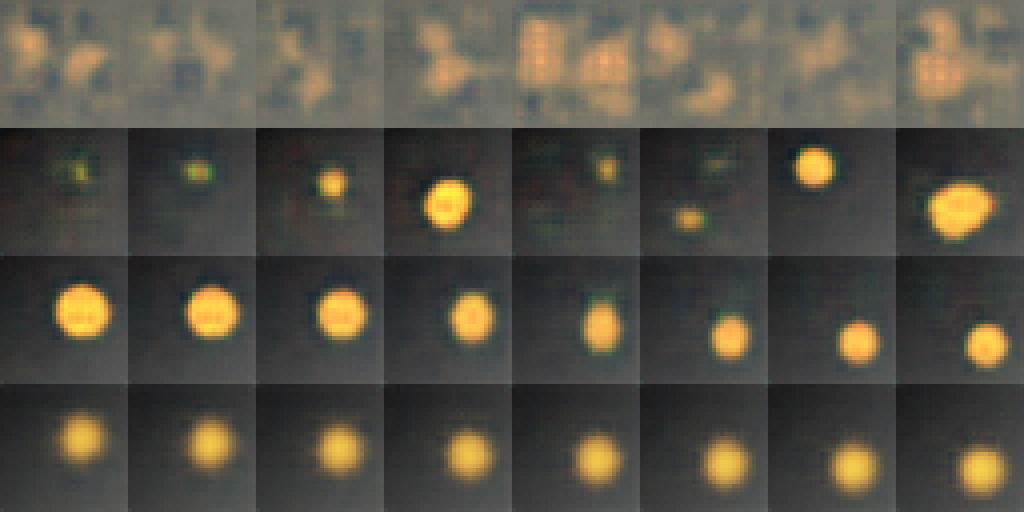

{'demo_seconds': 85.61}


In [6]:
# Демонстрационный вариант 1: lab08_demo.py выполняется целиком; вывод сохраняется в artifacts/demo/.
demo_started = time.perf_counter()
with capture_output() as demo_capture:
    get_ipython().run_line_magic("run", "lab08_demo.py")
demo_seconds = time.perf_counter() - demo_started
demo_capture.show()
(artifacts / "demo" / "demo_output.txt").write_text(demo_capture.stdout, encoding="utf-8")
shutil.move("comparison.png", artifacts / "demo" / "comparison_variant01.png")
display(Image.open(artifacts / "demo" / "comparison_variant01.png"))
print({"demo_seconds": round(demo_seconds, 2)})

In [7]:
# Сверка демонстрационного варианта с разделами 6.3–6.4 методички.
def jnum(value):
    return value if math.isfinite(value) else ("inf" if value > 0 else "-inf")

DEMO_REFERENCE = {  # A, s, B, Δ из таблицы 6.3
    "recon": (26.37, 0.61, 22.53, -3.84), "interp": (22.55, 0.48, 21.90, -0.65),
    "sample": (23.24, 0.56, 23.21, -0.03), "r2": (0.899, 0.022, 0.786, -0.114),
}
DEMO_DIAG_REFERENCE = {  # активные оси, реконструкция, интерполяция, сэмплы (seed 101), раздел 6.4
    "AE, beta=0": ("-", 26.24, 22.30, 12.86), "VAE, beta=1": ("7", 26.69, 22.68, 23.28), "VAE, beta=8": ("2", 22.24, 22.39, 23.41),
}
DEMO_COLLAPSE_REFERENCE = {"без разогрева": [26.5, 17.2, 25.7, 26.7, 24.7], "разогрев 10 эпох": [26.7, 26.9, 25.6, 26.9, 25.8]}

demo_rows = []
for name, a, s, b, d, q, sig in result["rows"]:
    ra, rs, rb, rd = DEMO_REFERENCE[name]
    demo_rows.append({"metric": name, "A": a, "s": s, "B": b, "d": d, "ratio": jnum(q), "sig_2s": sig,
                      "A_ref": ra, "s_ref": rs, "B_ref": rb, "d_ref": rd,
                      "A_within_2s_ref": abs(a - ra) <= 2 * rs, "B_within_2s_ref": abs(b - rb) <= 2 * rs})
diag_pattern = r"(AE, beta=0|VAE, beta=1|VAE, beta=8): разброс mu по осям \[([^\]]*)\]; активных осей (\S+); сэмплы PSNR ([\d.]+); интерполяция PSNR ([\d.]+); реконструкция PSNR ([\d.]+)"
demo_diag = {m[0]: {"mu_std": [float(v) for v in m[1].split()], "active": m[2], "sample": float(m[3]), "interp": float(m[4]), "recon": float(m[5]),
                    "reference": dict(zip(("active", "recon", "interp", "sample"), DEMO_DIAG_REFERENCE[m[0]]))}
             for m in re.findall(diag_pattern, demo_capture.stdout)}
demo_collapse = {m[0]: [float(v) for v in m[1].split(",")] for m in re.findall(r"(без разогрева|разогрев 10 эпох): \[([^\]]*)\]", demo_capture.stdout)}
assert len(demo_diag) == 3 and len(demo_collapse) == 2, (demo_diag.keys(), demo_collapse.keys())
demo_result = {"variant": result["variant"], "factor": result["factor"], "rows": demo_rows, "diagnostics": demo_diag,
               "collapse": {k: {"recon_by_seed": v, "reference": DEMO_COLLAPSE_REFERENCE[k]} for k, v in demo_collapse.items()},
               "demo_seconds": round(demo_seconds, 2)}
(artifacts / "demo" / "demo_variant01.json").write_text(json.dumps(demo_result, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
display(pd.DataFrame(demo_rows).round(3))
display(pd.DataFrame([{"модель": k, "активных осей": v["active"], "реконструкция": v["recon"], "интерполяция": v["interp"], "сэмплы": v["sample"],
                       "методичка (оси / рек. / инт. / сэмплы)": " / ".join(map(str, DEMO_DIAG_REFERENCE[k]))} for k, v in demo_diag.items()]))
for k, v in demo_collapse.items():
    print(f"{k}: {v} | методичка: {DEMO_COLLAPSE_REFERENCE[k]}")
print("Обучение на GPU не побитово детерминировано: сверяется картина в пределах разброса между seed, а не последний знак.")

,metric,A,s,B,d,ratio,sig_2s,A_ref,s_ref,B_ref,d_ref,A_within_2s_ref,B_within_2s_ref
0,recon,26.344,0.577,22.546,-3.797,6.586,True,26.370,0.610,22.530,-3.840,True,True
1,interp,22.614,0.409,21.984,-0.630,1.540,False,22.550,0.480,21.900,-0.650,True,True
2,sample,23.246,0.471,23.278,0.032,0.068,False,23.240,0.560,23.210,-0.030,True,True
3,r2,0.900,0.018,0.803,-0.097,5.272,True,0.899,0.022,0.786,-0.114,True,True


,модель,активных осей,реконструкция,интерполяция,сэмплы,методичка (оси / рек. / инт. / сэмплы)
0,"AE, beta=0",-,26.07,22.40,12.81,- / 26.24 / 22.3 / 12.86
1,"VAE, beta=1",6,26.77,22.89,23.73,7 / 26.69 / 22.68 / 23.28
2,"VAE, beta=8",2,22.25,22.41,23.46,2 / 22.24 / 22.39 / 23.41


без разогрева: [26.5, 17.2, 25.5, 26.1, 26.1] | методичка: [26.5, 17.2, 25.7, 26.7, 24.7]
разогрев 10 эпох: [26.7, 26.8, 25.5, 26.5, 25.7] | методичка: [26.7, 26.9, 25.6, 26.9, 25.8]
Обучение на GPU не побитово детерминировано: сверяется картина в пределах разброса между seed, а не последний знак.


## Вариант 7: «диск и полоса» × β = 1 → 8

In [8]:
# Обязательный вызов из методички: V.variant_summary(7). Обёртка над V.run только записывает метрики каждого запуска.
run_log = []
_original_run = V.run

def _logged_run(kind, cfg, seed):
    metrics = _original_run(kind, cfg, seed)
    run_log.append({"beta": cfg["beta"], "seed": seed, **metrics})
    return metrics

V.run = _logged_run
try:
    summary_started = time.perf_counter()
    summary = V.variant_summary(VARIANT)
    summary_seconds = time.perf_counter() - summary_started
finally:
    V.run = _original_run
assert summary["variant"] == VARIANT and summary["ctx"] == DATASET and summary["factor"] == FACTOR

print("Вариант", summary["variant"], "набор", KIND, "фактор", summary["factor"])
for name, a, s, b, d, q, sig in summary["rows"]:
    print(f"{name:7s} A={a:7.3f} s={s:6.3f} B={b:7.3f} d={d:+7.3f} |d|/s={q:7.2f} 2s={'да' if sig else 'нет'}")

METRIC_NAMES = {"recon": "реконструкция, дБ", "interp": "интерполяция, дБ", "sample": "сэмплы, дБ", "r2": "R² факторов"}
metric_rows = [{"metric": m, "A": a, "s": s, "B": b, "d": d, "ratio": jnum(q), "sig_2s": sig} for m, a, s, b, d, q, sig in summary["rows"]]
per_seed_df = pd.DataFrame([dict(row, mode="A" if row["beta"] == A_CFG["beta"] else "B") for row in run_log])
per_seed_df = per_seed_df[["mode", "seed", "beta", *METRICS]]
per_seed_df.to_csv(artifacts / "per_seed_metrics.csv", index=False)
for m, a, s, b, *_ in summary["rows"]:
    assert np.isclose(np.mean(per_seed_df[per_seed_df["mode"] == "A"][m]), a) and np.isclose(np.mean(per_seed_df[per_seed_df["mode"] == "B"][m]), b)

metrics = {"variant": VARIANT, "dataset": KIND, "factor": FACTOR, "seeds": SEEDS, "mode_a": A_CFG, "mode_b": B_CFG,
           "rows": metric_rows, "summary_seconds": round(summary_seconds, 2)}
(artifacts / "metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
display(pd.DataFrame([{"метрика": METRIC_NAMES[r["metric"]], "A (β = 1)": r["A"], "s": r["s"], "B (β = 8)": r["B"], "Δ": r["d"],
                       "|Δ|/s": r["ratio"], "|Δ| > 2s": "да" if r["sig_2s"] else "нет"} for r in metric_rows]).round(3))
display(per_seed_df.round(3))

Вариант 7 набор disc_rect фактор beta_1_to_8
recon   A= 25.788 s= 0.494 B= 21.427 d= -4.361 |d|/s=   8.82 2s=да
interp  A= 22.703 s= 0.335 B= 21.516 d= -1.187 |d|/s=   3.54 2s=да
sample  A= 22.633 s= 0.180 B= 22.167 d= -0.467 |d|/s=   2.59 2s=да
r2      A=  0.926 s= 0.011 B=  0.845 d= -0.081 |d|/s=   7.64 2s=да


,метрика,A (β = 1),s,B (β = 8),Δ,|Δ|/s,|Δ| > 2s
0,"реконструкция, дБ",25.788,0.494,21.427,-4.361,8.822,да
1,"интерполяция, дБ",22.703,0.335,21.516,-1.187,3.539,да
2,"сэмплы, дБ",22.633,0.180,22.167,-0.467,2.594,да
3,R² факторов,0.926,0.011,0.845,-0.081,7.637,да


,mode,seed,beta,recon,interp,sample,r2
0,A,101,1.0,26.061,22.714,22.860,0.924
1,B,101,8.0,21.739,21.946,22.690,0.886
2,A,102,1.0,26.530,23.261,22.613,0.942
3,B,102,8.0,21.757,21.629,22.243,0.786
4,A,103,1.0,25.429,22.539,22.404,0.929
5,B,103,8.0,21.373,21.588,22.181,0.863
6,A,104,1.0,25.400,22.621,22.757,0.924
7,B,104,8.0,21.473,21.467,22.176,0.792
8,A,105,1.0,25.518,22.379,22.533,0.912
9,B,105,8.0,20.791,20.951,21.544,0.898


In [9]:
# Диагностика (шаги 5 и 8 плана): разброс μ, KL и активные оси у AE (β = 0) и VAE (β = 1, 8), seed 101; активные оси A и B по каждому seed.
Xtr, Xte, Ftr, Fte = L.dataset(KIND)

@torch.no_grad()
def axis_stats(model):
    mu, lv = model.encode_dist(Xte)
    kl_axis = (-0.5 * (1 + lv - mu ** 2 - lv.exp())).mean(0)
    return mu.std(0).cpu().numpy(), kl_axis.cpu().numpy()

diagnostics = {}
for name, beta in (("AE, beta=0", 0.0), ("VAE, beta=1", 1.0), ("VAE, beta=8", 8.0)):
    model = V.get_model(KIND, dict(V.BASE, beta=beta), 101)
    mu_std, kl_axis = axis_stats(model)
    m = V.metrics(model, KIND, "lin", 1.0, 101)
    diagnostics[name] = {"beta": beta, "mu_std": [round(float(v), 3) for v in mu_std], "kl_axis_nat": [round(float(v), 3) for v in kl_axis],
                         "active_axes": int((kl_axis > ACTIVE_KL).sum()) if beta > 0 else None, **m}
    print(f"{name}: разброс mu по осям {mu_std.round(2)}; KL по осям {kl_axis.round(2)}; активных осей {diagnostics[name]['active_axes'] if beta > 0 else '-'}; "
          f"сэмплы PSNR {m['sample']:.2f}; интерполяция PSNR {m['interp']:.2f}; реконструкция PSNR {m['recon']:.2f}; R² {m['r2']:.3f}")

active_by_seed = []
for seed in SEEDS:
    for mode, cfg in (("A", A_CFG), ("B", B_CFG)):
        mu_std, kl_axis = axis_stats(V.get_model(KIND, cfg, seed))
        active_by_seed.append({"mode": mode, "seed": seed, "active_axes": int((kl_axis > ACTIVE_KL).sum()),
                               "kl_total_nat": round(float(kl_axis.sum()), 2), "mu_std_max": round(float(mu_std.max()), 2)})
active_df = pd.DataFrame(active_by_seed)
display(active_df.pivot(index="seed", columns="mode", values="active_axes").rename(columns={"A": "активных осей A (β = 1)", "B": "активных осей B (β = 8)"}))
(artifacts / "diagnostics.json").write_text(json.dumps(
    {"dataset": KIND, "active_kl_threshold_nat": ACTIVE_KL, "seed_101": diagnostics, "active_axes_by_seed": active_by_seed},
    ensure_ascii=False, indent=2), encoding="utf-8")

AE, beta=0: разброс mu по осям [3.04 4.65 7.16 3.53 6.29 5.42 5.61 5.14]; KL по осям [44.   11.92 32.31 37.8  30.67 15.13 23.12 43.53]; активных осей -; сэмплы PSNR 12.71; интерполяция PSNR 24.04; реконструкция PSNR 26.85; R² 0.966
VAE, beta=1: разброс mu по осям [0.06 1.03 0.95 0.9  1.07 0.91 0.04 1.02]; KL по осям [0.01 1.98 1.28 1.17 2.09 1.18 0.   1.76]; активных осей 6; сэмплы PSNR 22.86; интерполяция PSNR 22.71; реконструкция PSNR 26.06; R² 0.924
VAE, beta=8: разброс mu по осям [0.05 0.04 0.03 0.82 0.04 0.8  0.97 0.05]; KL по осям [0.   0.   0.   0.6  0.   0.57 1.15 0.  ]; активных осей 3; сэмплы PSNR 22.69; интерполяция PSNR 21.95; реконструкция PSNR 21.74; R² 0.886


mode,активных осей A (β = 1),активных осей B (β = 8)
seed,,
101,6,3
102,6,4
103,6,3
104,6,4
105,6,4


2905

In [10]:
# Эталон «средняя картинка» из ЛР07 для набора варианта: средняя обучающая сцена, одинаковая для всех входов.
mean_image = Xtr.mean(0, keepdim=True).expand_as(Xte)
baseline_psnr = L.psnr_images(mean_image, Xte)
recon_a, recon_b = metric_rows[0]["A"], metric_rows[0]["B"]
baseline = {"dataset": KIND, "baseline_psnr": baseline_psnr,
            "recon_gain_a_db": recon_a - baseline_psnr, "recon_gain_b_db": recon_b - baseline_psnr,
            "interp_gain_a_db": metric_rows[1]["A"] - baseline_psnr, "interp_gain_b_db": metric_rows[1]["B"] - baseline_psnr}
(artifacts / "baseline.json").write_text(json.dumps(baseline, ensure_ascii=False, indent=2), encoding="utf-8")
print("эталон «средняя картинка», PSNR на тесте:", round(baseline_psnr, 3))
print(f"выигрыш реконструкции над эталоном: A = {baseline['recon_gain_a_db']:+.2f} дБ, B = {baseline['recon_gain_b_db']:+.2f} дБ")

эталон «средняя картинка», PSNR на тесте: 16.892
выигрыш реконструкции над эталоном: A = +8.90 дБ, B = +4.53 дБ


In [11]:
# Намеренная ошибка 1 (как в демо): β = 1 «сразу» без разогрева KL-члена против разогрева 10 эпох; метрики по каждому seed.
collapse = {}
for name, wu in (("без разогрева", 1e-9), ("разогрев 10 эпох", 10)):
    rows_c = []
    for s in SEEDS:
        torch.manual_seed(s)
        m = V.train_vae(V.ConvVAE(8).to(L.DEVICE), Xtr, 1.0, 30, seed=s, warmup=wu)
        mu_std, kl_axis = axis_stats(m)
        rows_c.append({"seed": s, **V.metrics(m, KIND, "lin", 1.0, s), "active_axes": int((kl_axis > ACTIVE_KL).sum())})
    collapse[name] = rows_c
    print(f"{name}: реконструкция {[round(r['recon'], 1) for r in rows_c]}; R² {[round(r['r2'], 3) for r in rows_c]}; активных осей {[r['active_axes'] for r in rows_c]}")

без разогрева: реконструкция [26.0, 25.8, 25.1, 25.6, 16.9]; R² [0.814, 0.804, 0.874, 0.781, 0.328]; активных осей [5, 6, 6, 5, 0]
разогрев 10 эпох: реконструкция [26.0, 26.5, 25.4, 25.4, 25.5]; R² [0.924, 0.936, 0.928, 0.925, 0.914]; активных осей [6, 6, 6, 6, 6]


In [12]:
# Намеренная ошибка 2 (как в демо): сэмплы из N(0, I) у обычного автокодировщика. Исправление — сэмплы из распределения μ на обучающих сценах.
@torch.no_grad()
def nearest_psnr(model, z):
    xs = model.decode(z).flatten(1)
    mse = torch.cdist(xs, Xte.flatten(1)).pow(2) / xs.shape[1]
    return float((10 * torch.log10(1.0 / mse.min(1).values.clamp_min(1e-10))).mean())

sampling = {}
g = torch.Generator(device="cpu").manual_seed(1000 + 101)
eps = torch.randn((V.N_SAMPLES, 8), generator=g).to(L.DEVICE)
for name, beta in (("AE, beta=0", 0.0), ("VAE, beta=1", 1.0)):
    model = V.get_model(KIND, dict(V.BASE, beta=beta), 101)
    with torch.no_grad():
        mu_tr = model.encode(Xtr)
    sampling[name] = {"prior_N01": nearest_psnr(model, eps), "fitted_to_train_mu": nearest_psnr(model, mu_tr.mean(0) + eps * mu_tr.std(0))}
    print(f"{name}: сэмплы из N(0, I) — {sampling[name]['prior_N01']:.2f} дБ; из N(среднее μ, разброс μ) — {sampling[name]['fitted_to_train_mu']:.2f} дБ")

intentional_error = {
    "error_1_no_kl_warmup": {"description": "VAE trained with beta = 1 from the first step and judged only by the mean over seeds",
                             "by_seed": collapse,
                             "diagnosis": "posterior collapse: recon equals the mean-image baseline, R^2 near 0, no active axes",
                             "fix": "linear KL warm-up over the first 10 epochs; inspect every seed"},
    "error_2_ae_prior_samples": {"description": "samples from N(0, I) decoded by a plain autoencoder (beta = 0)", "nearest_psnr_db": sampling,
                                 "diagnosis": "AE latent codes are not matched to N(0, I); samples fall where the decoder was not trained",
                                 "fix": "use the KL term, or sample from the distribution of mu estimated on training scenes"},
    "baseline_psnr": baseline_psnr,
}
(artifacts / "intentional_error.json").write_text(json.dumps(intentional_error, ensure_ascii=False, indent=2), encoding="utf-8")

AE, beta=0: сэмплы из N(0, I) — 12.71 дБ; из N(среднее μ, разброс μ) — 20.21 дБ
VAE, beta=1: сэмплы из N(0, I) — 22.86 дБ; из N(среднее μ, разброс μ) — 22.98 дБ


3303

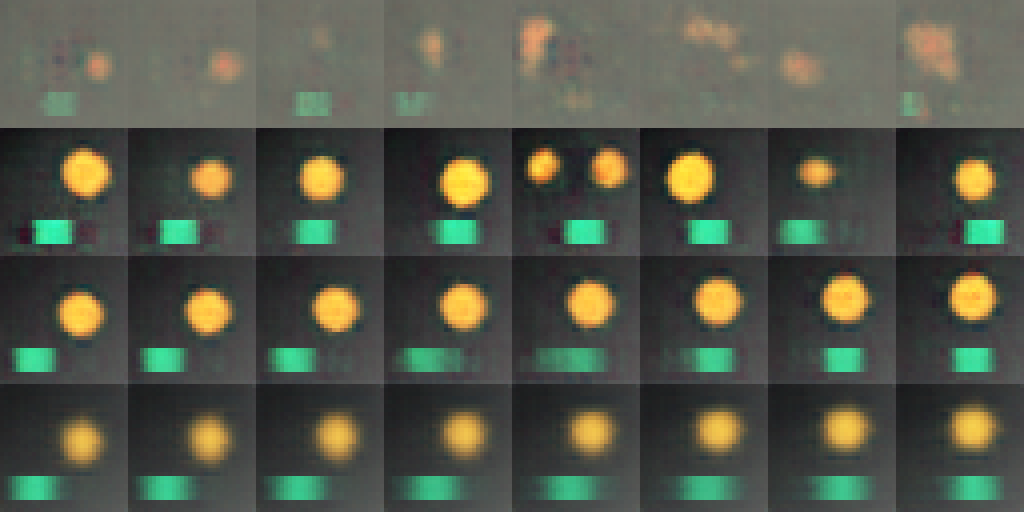

In [13]:
# Лист сравнения comparison.png — код раздела 6.2 методички, N = 7: сэмплы AE и VAE β = 1, линейный путь между тестовыми сценами 0 и 2 при β = 1 и β = 8.
N = 7
c, k = (N - 1) // 6, (N - 1) % 6
kind = L.KINDS[c]
Xte = L.dataset(kind)[1]
from PIL import Image
def strip(imgs):
    return np.concatenate(list(imgs.permute(0, 2, 3, 1).cpu().numpy()), axis=1)
g = torch.Generator(device="cpu").manual_seed(5)
z = torch.randn((8, 8), generator=g).to(L.DEVICE)
rows = []
with torch.no_grad():
    for beta in (0.0, 1.0):
        rows.append(strip(V.get_model(kind, dict(V.BASE, beta=beta), 101).decode(z)))
    for beta in (1.0, 8.0):
        model = V.get_model(kind, dict(V.BASE, beta=beta), 101)
        za, zb = model.encode(Xte[0:1]), model.encode(Xte[2:3])
        t = torch.linspace(0, 1, 8, device=L.DEVICE).unsqueeze(1)
        rows.append(strip(model.decode((1 - t) * za + t * zb)))
sheet = Image.fromarray((np.concatenate(rows, axis=0) * 255).round().astype("uint8")).resize((8 * 32 * 4, 4 * 32 * 4), Image.NEAREST)
sheet.save("comparison.png")
sheet

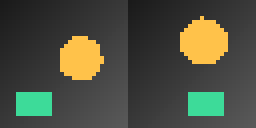

,диск x,диск y,радиус,полоса x
сцена 0 (t = 0),0.77,0.62,0.71,0.14
сцена 2 (t = 1),0.69,0.08,0.89,0.77


In [14]:
# Копия comparison.png в artifacts/ и концы пути: тестовые сцены 0 и 2 с их факторами.
shutil.copyfile("comparison.png", artifacts / "comparison.png")
ends = (Xte[[0, 2]].permute(0, 2, 3, 1).cpu().numpy() * 255).round().astype("uint8")
Image.fromarray(np.concatenate(list(ends), axis=1)).resize((2 * 32 * 4, 32 * 4), Image.NEAREST).save(artifacts / "path_endpoints.png")
path_factors = pd.DataFrame(Fte[[0, 2]].cpu().numpy(), columns=["диск x", "диск y", "радиус", "полоса x"], index=["сцена 0 (t = 0)", "сцена 2 (t = 1)"]).round(2)
path_factors.to_csv(artifacts / "path_factors.csv")
display(Image.open(artifacts / "path_endpoints.png"))
display(path_factors)

In [15]:
# Классификация по заранее записанному допуску; сравнение с критерием 2s и чувствительность к допуску (×0.5, ×2).
def classify(metric, d, scale=1.0):
    if abs(d) <= TOLERANCE[metric] * scale:
        return "нейтрально"
    return "улучшение" if d > 0 else "ухудшение"

classification = []
for r in metric_rows:
    label = classify(r["metric"], r["d"])
    classification.append({
        "metric": r["metric"], "change": r["d"], "tolerance": TOLERANCE[r["metric"]], "class": label, "sig_2s": r["sig_2s"],
        "2s_and_tolerance_agree": r["sig_2s"] == (label != "нейтрально"),
        "class_tolerance_x0_5": classify(r["metric"], r["d"], 0.5), "class_tolerance_x2": classify(r["metric"], r["d"], 2.0),
    })
(artifacts / "classification.json").write_text(json.dumps({"variant": VARIANT, "rows": classification}, ensure_ascii=False, indent=2), encoding="utf-8")
display(pd.DataFrame([{
    "метрика": METRIC_NAMES[row["metric"]], "Δ": f"{row['change']:+.3f}", "допуск": f"±{row['tolerance']}", "класс": row["class"],
    "|Δ| > 2s": "да" if row["sig_2s"] else "нет", "2s и допуск согласуются": "да" if row["2s_and_tolerance_agree"] else "нет",
    "допуск ×0.5": row["class_tolerance_x0_5"], "допуск ×2": row["class_tolerance_x2"],
} for row in classification]))

,метрика,Δ,допуск,класс,|Δ| > 2s,2s и допуск согласуются,допуск ×0.5,допуск ×2
0,"реконструкция, дБ",-4.361,±1.0,ухудшение,да,да,ухудшение,ухудшение
1,"интерполяция, дБ",-1.187,±1.0,ухудшение,да,да,ухудшение,нейтрально
2,"сэмплы, дБ",-0.467,±1.0,нейтрально,да,нет,нейтрально,нейтрально
3,R² факторов,-0.081,±0.05,ухудшение,да,да,ухудшение,нейтрально


## Ручная визуальная проверка

Посмотрите на `comparison.png`: строка 1 — сэмплы обычного автокодировщика (β = 0), строка 2 — сэмплы VAE β = 1 (те же z), строка 3 — линейный путь между тестовыми сценами 0 и 2 при β = 1, строка 4 — тот же путь при β = 8. Концы пути и их факторы выведены выше. Проверьте, что по пути интерполяции диск движется, а полоса смещается, не исчезая; отметьте, похожи ли сэмплы на сцены набора.

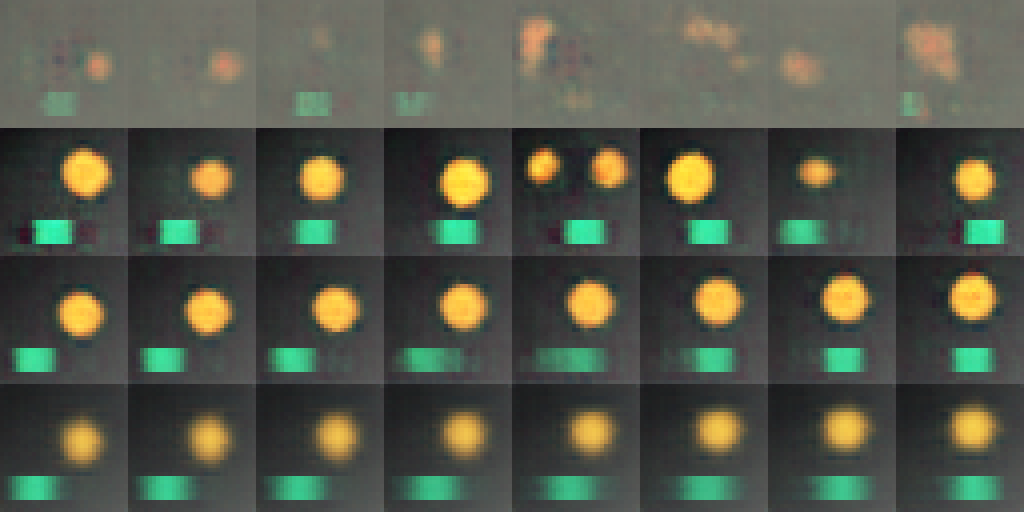

VISUAL_CHECK: {'ae_samples_look_like_scenes': False, 'vae_samples_look_like_scenes': True, 'path_beta1_ok': True, 'path_beta8_ok': True, 'notes': 'Сэмплы AE из N(0, I): серые размытые пятна с бледными оранжевыми следами, диск и полоса не читаются. Сэмплы VAE β = 1: в 7 из 8 — узнаваемые сцены с диском и полосой, в пятом сэмпле два диска (невозможная сцена). Путь β = 1: диск плавно смещается вверх и чуть увеличивается, полоса переходит слева направо; в средних кадрах полоса растянута и полупрозрачна, но не исчезает. Путь β = 8: та же траектория, но диск заметно размыт, полоса в середине пути сильнее растянута в ленту.'}


In [19]:
display(Image.open(artifacts / "comparison.png"))

# Заполните только после фактического просмотра, затем перезапустите эту и последующие ячейки.
VISUAL_CHECK = {"ae_samples_look_like_scenes": False, "vae_samples_look_like_scenes": True, "path_beta1_ok": True, "path_beta8_ok": True, "notes": "Сэмплы AE из N(0, I): серые размытые пятна с бледными оранжевыми следами, диск и полоса не читаются. Сэмплы VAE β = 1: в 7 из 8 — узнаваемые сцены с диском и полосой, в пятом сэмпле два диска (невозможная сцена). Путь β = 1: диск плавно смещается вверх и чуть увеличивается, полоса переходит слева направо; в средних кадрах полоса растянута и полупрозрачна, но не исчезает. Путь β = 8: та же траектория, но диск заметно размыт, полоса в середине пути сильнее растянута в ленту."}
visual_done = all(VISUAL_CHECK[key] is not None for key in ("ae_samples_look_like_scenes", "vae_samples_look_like_scenes", "path_beta1_ok", "path_beta8_ok")) and bool(VISUAL_CHECK["notes"])
print("VISUAL_CHECK:", VISUAL_CHECK if visual_done else "PENDING")

In [20]:
# Паспорт эксперимента — все измеряемые поля берутся из этого сеанса.
experiment_passport = {
    "status": "COMPLETE" if visual_done else "PARTIAL",
    "variant": VARIANT, "dataset": KIND, "dataset_factors": L.N_FACTORS[KIND], "factor": FACTOR, "seeds": SEEDS,
    "hypothesis_recorded_at": HYPOTHESIS_RECORDED_AT,
    "hypothesis": "beta = 8 instead of 1 lowers recon by more than 1 dB, R^2 by more than 0.05 and interp by more than 1 dB; samples change within ±1 dB; active axes >= 4 at beta = 1 and < 4 at beta = 8",
    "tolerance": TOLERANCE, "direction": {m: "increase_is_improvement" for m in METRICS}, "control_metrics": [],
    "model": {"library": "lab08_lib.ConvVAE", "optimizer": "Adam", "lr": 2e-3, "batch": 128, "epochs": A_CFG["epochs"], "kl_warmup_epochs": 10},
    "data": {"generator": "lab07_lib.render", "data_seed": 7, "n_train": int(Xtr.shape[0]), "n_test": int(Xte.shape[0]), "image": "3x32x32",
             "interp_pairs": V.N_PAIRS, "samples": V.N_SAMPLES},
    "mode_a": A_CFG, "mode_b": B_CFG, "changed_fields": changed,
    "environment": environment, "library_sha256": library_sha256,
    "timings_seconds": {"demo_total": round(demo_seconds, 2), "variant_summary": round(summary_seconds, 2)},
    "metrics": metric_rows, "classification": classification, "baseline": baseline,
    "diagnostics_seed_101": diagnostics, "active_axes_by_seed": active_by_seed,
    "visual_check": VISUAL_CHECK,
    "demo_reproduction": demo_result, "intentional_error": intentional_error,
    "limitations": [
        "synthetic 32x32 scenes with a smooth background; conclusions do not transfer to photographs without checking",
        "one architecture, one dataset, one factor, five seeds, 30 epochs",
        "GPU training is not bitwise deterministic; values reproduce within the between-seed spread",
        "nearest-neighbour PSNR of samples does not check sample diversity",
        "R^2 is a linear measure and does not prove disentanglement",
    ],
    "license": "synthetic data generated by lab07_lib.py; no external data or pretrained weights",
    "executed_at_utc": datetime.now(timezone.utc).isoformat(),
}
(artifacts / "passport.json").write_text(json.dumps(experiment_passport, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")

environment_lines = [
    "STATUS=ACTUAL", "execution_environment=Google Colab", f"actual_gpu={environment['gpu']}",
    f"cuda_runtime={environment['cuda_runtime']}", f"python={environment['python']}",
    *[f"{name}={version}" for name, version in environment["packages"].items()],
    f"platform={environment['platform']}", f"cuda_available={environment['cuda_available']}", f"device={V.DEVICE}",
]
(reports / "environment.txt").write_text("\n".join(environment_lines) + "\n", encoding="utf-8")
print(json.dumps({key: experiment_passport[key] for key in ("status", "timings_seconds")}, ensure_ascii=False, indent=2))

{
  "status": "COMPLETE",
  "timings_seconds": {
    "demo_total": 85.61,
    "variant_summary": 35.83
  }
}


In [21]:
# Итоговая проверка файлов, JSON, PNG и чек-листа методички.
required_files = [
    artifacts / "metrics.json", artifacts / "per_seed_metrics.csv", artifacts / "classification.json", artifacts / "diagnostics.json",
    artifacts / "baseline.json", artifacts / "intentional_error.json", artifacts / "comparison.png",
    artifacts / "path_endpoints.png", artifacts / "path_factors.csv",
    artifacts / "demo" / "demo_variant01.json", artifacts / "demo" / "demo_output.txt", artifacts / "demo" / "comparison_variant01.png",
    artifacts / "passport.json", reports / "environment.txt",
]
for path in required_files:
    assert path.is_file() and path.stat().st_size > 0, f"Missing or empty: {path}"
for path in required_files:
    if path.suffix == ".json":
        json.loads(path.read_text(encoding="utf-8"))
for path in (artifacts / "comparison.png", artifacts / "demo" / "comparison_variant01.png"):
    with Image.open(path) as check_image:
        check_image.verify()
    with Image.open(path) as check_image:
        assert check_image.format == "PNG" and check_image.size == (1024, 512), (path, check_image.size)

assert len(metric_rows) == 4 and len(per_seed_df) == 2 * len(SEEDS)
assert all(math.isfinite(r[m]) for r in run_log for m in METRICS), "NaN в метриках"
assert visual_done, "Заполните VISUAL_CHECK после фактического просмотра"
assert experiment_passport["status"] == "COMPLETE"

checklist = {
    "hypothesis_and_tolerance_before_run": True,
    "actual_gpu_and_versions_recorded": V.DEVICE == "cuda",
    "libraries_match_methodology_sha256": library_sha256 == EXPECTED_SHA256,
    "exactly_one_factor_changed": changed == ["beta"],
    "five_seed_series": list(V.SEEDS) == SEEDS,
    "control_metrics_marked": True,
    "mu_spread_and_active_axes_reported": len(diagnostics) == 3 and len(active_by_seed) == 2 * len(SEEDS),
    "ae_prior_samples_diagnosed": "AE, beta=0" in sampling,
    "comparison_png_saved": True,
    "classification_by_tolerance_saved": True,
    "demo_variant_executed_and_compared": bool(demo_rows),
    "visual_check_done": visual_done,
    "passport_complete": experiment_passport["status"] == "COMPLETE",
}
print(json.dumps(checklist, ensure_ascii=False, indent=2))
assert all(checklist.values())
print("FULL CHECKLIST: PASS")

{
  "hypothesis_and_tolerance_before_run": true,
  "actual_gpu_and_versions_recorded": true,
  "libraries_match_methodology_sha256": true,
  "exactly_one_factor_changed": true,
  "five_seed_series": true,
  "control_metrics_marked": true,
  "mu_spread_and_active_axes_reported": true,
  "ae_prior_samples_diagnosed": true,
  "comparison_png_saved": true,
  "classification_by_tolerance_saved": true,
  "demo_variant_executed_and_compared": true,
  "visual_check_done": true,
  "passport_complete": true
}
FULL CHECKLIST: PASS


In [22]:
# Архив результатов для переноса в репозиторий: artifacts/, reports/ и записанные библиотеки.
import zipfile
with zipfile.ZipFile("lab08_results.zip", "w", zipfile.ZIP_DEFLATED) as archive:
    for path in sorted([*artifacts.rglob("*"), *reports.rglob("*")]):
        if path.is_file():
            archive.write(path)
    for name in EXPECTED_SHA256:
        archive.write(name)
print("lab08_results.zip:", round(pathlib.Path("lab08_results.zip").stat().st_size / 1024), "KiB")
try:
    from google.colab import files
    files.download("lab08_results.zip")
except ImportError:
    pass

lab08_results.zip: 168 KiB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>